# Session 7: Biodiversity Impacts & Raster Analysis

**Goal:** Assess the ecological impact of data centers by overlaying them with biodiversity data (MOBI Species Richness).

Datasets:
1.  **Data Centers**: Locations from Cloud Regions.
2.  **MOBI Species Richness**: A raster dataset representing species richness (Taxonomic Groups) derived from MaxEnt models.

In [1]:
import rasterio
import rioxarray
import pandas as pd
import ibis
from ibis import _

ibis.options.interactive = True

## 1. Load Data

Load data centers and the biodiversity raster.

In [2]:
# Data Centers
url = "https://s3-west.nrp-nautilus.io/public-datacenters/data_centers.csv"
dcs = ibis.read_csv(url).filter(_.country == 'United States')

# Determine if latitude needs casting (likely inferred as string)
dcs = dcs.mutate(latitude=dcs.latitude.cast("float"))

df_dcs = dcs.to_pandas()

# Biodiversity Raster (Cloud Optimized GeoTIFF or standard Tif accessible via HTTP)
tif_url = "https://minio.carlboettiger.info/public-mobi/mobi-species-richness.tif"

# Open with Rasterio
# Note: ensuring we can read from URL. If environment blocks it, you may need to download locally first.
src = rasterio.open(tif_url)

## 2. Visualize Biodiversity Map

Let's look at the species richness map.

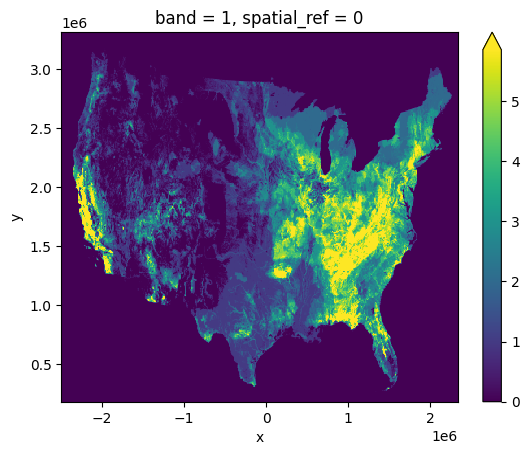

In [3]:
# Use rioxarray for plotting
rds = rioxarray.open_rasterio(tif_url)

# Downsample for quick visualization if the file is large
rds_downsampled = rds.coarsen(x=10, y=10, boundary="trim").mean()
rds_downsampled.plot(robust=True, cmap="viridis")

## 3. Extract Raster Values (Sampling)

We extract the pixel value (Species Richness) at each data center location.

In [4]:
# Prepare coordinates (Longitude, Latitude)
# Check if raster CRS matches data (usually WGS84 or similar); if not, reproject points.
print(f"Raster CRS: {src.crs}")

coords = [(x, y) for x, y in zip(df_dcs.longitude, df_dcs.latitude)]

# Sample
df_dcs['species_richness'] = [x[0] for x in src.sample(coords)]

df_dcs[['provider', 'metro', 'region_name', 'species_richness']].head()

Raster CRS: EPSG:5070


,provider,metro,region_name,species_richness
0,Microsoft Azure,Atlanta,East US 3 (Atlanta),0
1,Microsoft Azure,Austin,US Gov Texas,0
2,Google Cloud,Charleston,South Carolina,0
3,Microsoft Azure,Cheyenne,West Central US (Cheyenne),0
4,Microsoft Azure,Chicago,North Central US (Chicago),0


## 4. Impact Assessment

Identify facilities in high-biodiversity areas.

In [5]:
top_impact = df_dcs.sort_values("species_richness", ascending=False).head(10)
top_impact[['provider', 'metro', 'region_name', 'species_richness']]

,provider,metro,region_name,species_richness
0,Microsoft Azure,Atlanta,East US 3 (Atlanta),0
183,Microsoft Azure,Las Vegas,None,0
199,IBM Cloud,Miami,None,0
198,Google Cloud,Miami,None,0
197,Amazon Web Services,Miami,None,0
196,Oracle Cloud,Los Angeles,None,0
195,Oracle Cloud,Los Angeles,None,0
194,Microsoft Azure,Los Angeles,None,0
193,Microsoft Azure,Los Angeles,None,0
192,IBM Cloud,Los Angeles,None,0


## Discussion

Does the location of data centers correlate with high biodiversity areas? What ecological risks might be present in the top-ranked locations?